## 0. Config & Imports

In [68]:

# How to handle participants who used the website more than once (presumably for mistake or curiosity):
#
#   "max_deliberation_time" -> keep only the row with the highest
#                              deliberation_time for each participant               -> Don't lose any data, but some entry 
#                                                                                       could be mistakely refearred to a condition
#
#   "unique"                -> drop every participant who appears more than once    -> We lose some data(unethical), but we are sure that every 
#                                                                                       entry is correctly referred to a condition

#CONFIG_reused_website_cases = "max_deliberation_time"
CONFIG_reused_website_cases = "unique"

In [69]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.ticker import PercentFormatter


In [70]:
webpage_data = pd.read_csv("webpage_data.csv")
questionnaire_data = pd.read_csv("questionnaire_data.csv")

data = pd.merge(webpage_data, questionnaire_data, on="participant_id", how= "inner")

## 1. Data Preparation

Before conducting the statistical analysis, the dataset is inspected and prepared.

The first step consists of checking the dataset structure, changing automatic google sheet column names, cutting useless data and verifying the data types of the variables.

Some auxiliary columns are created using the data we have

In [71]:
data = data.rename(columns={
    "  Which age group do you belong to?   ":"age_group",
    "What are you using for this test?":"device_type",
    "How often do you browse or make purchases on online shopping websites?\"": "purchase_frequency",
    "On average, how many hours per day do you spend using a computer (for work, study, or leisure)?":"computer_usage",
    "How much do you feel the website tried to pressure you into making an account/ subscribe ":"pressure_perception",
    "To what extent did you find the decline option sarcastic or mocking?":"sarcastic_mocking_extent",
    "Did you read the pop up?":"have_read_popup",
    "MENTAL DEMAND":"nasa_mental_demand",
    "TEMPORAL DEMAND":"nasa_temporal_demand",
    "FRUSTRATION LEVEL":"nasa_frustration",
    "PERFORMANCE":"nasa_performance",
    "EFFORT":"nasa_effort",
    "WILLINGNESS TO RECCOMEND":"willingness_to_recommend"
                            })

In [72]:
quantitative_data=data[['timestamp','participant_id','condition','action_taken','deliberation_time_sec','email_entered','checkboxes_checked','is_test','nasa_mental_demand','nasa_temporal_demand','nasa_performance','nasa_effort','nasa_frustration','willingness_to_recommend','age_group','device_type','purchase_frequency','computer_usage','pressure_perception','sarcastic_mocking_extent','have_read_popup']]

In [73]:
acceptance_mapping = {
    "clicked_submit_decline": 0,
    "clicked_submit_accept": 1,
    "clicked_decline_text_link": 0,
    "clicked_close_x_button": 0 #TODO: delete it if we decide to delete pilot testings -> This is not a case anymore
}

quantitative_data["acceptance"] = quantitative_data["action_taken"].map(acceptance_mapping).astype("Int64")

In [74]:
#quantitative_data[quantitative_data["condition"] == "Control"]

### Multiple website usage from the same user
Some particiipant opened the website multiple times, we suppose by mistake or curiosity, 
2 Ways can be implemented to clean those esntries:
 A: Cut the entire participant -> safe data but we lose many tests (also unethical)
 B: We keep only the use with the longest deliberation time -> some questionnaire could be refeared to an unexpected condition
    We also assure that the usage is not refeared to a future discovery of the test by chacking the website usage timestamp with the questionnaire completed timestamp

CHANGE IT IN CONFIG SECTION

In [75]:
if CONFIG_reused_website_cases == "max_deliberation_time":
    quantitative_data = quantitative_data[quantitative_data['deliberation_time_sec'] == quantitative_data.groupby('participant_id')['deliberation_time_sec'].transform('max')]
elif CONFIG_reused_website_cases == "unique":
    quantitative_data = quantitative_data[~quantitative_data.duplicated(subset='participant_id', keep=False)]
#quantitative_data.info()

# 2. Quick overview on data

In [76]:
quantitative_data.info()

<class 'pandas.DataFrame'>
Index: 11 entries, 0 to 35
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   timestamp                 11 non-null     str    
 1   participant_id            11 non-null     str    
 2   condition                 11 non-null     str    
 3   action_taken              11 non-null     str    
 4   deliberation_time_sec     11 non-null     float64
 5   email_entered             11 non-null     bool   
 6   checkboxes_checked        11 non-null     str    
 7   is_test                   0 non-null      str    
 8   nasa_mental_demand        8 non-null      float64
 9   nasa_temporal_demand      8 non-null      float64
 10  nasa_performance          1 non-null      float64
 11  nasa_effort               8 non-null      float64
 12  nasa_frustration          8 non-null      float64
 13  willingness_to_recommend  8 non-null      float64
 14  age_group                 9 

In [77]:
quantitative_data.head()

,timestamp,participant_id,condition,action_taken,deliberation_time_sec,email_entered,checkboxes_checked,is_test,nasa_mental_demand,nasa_temporal_demand,...,nasa_frustration,willingness_to_recommend,age_group,device_type,purchase_frequency,computer_usage,pressure_perception,sarcastic_mocking_extent,have_read_popup,acceptance
0,2026-11-11T10:29:59.876Z,P_9FKETYLM,v1_condition,clicked_close_x_button,3.80,False,none,NaN,1.0,1.0,...,1.0,4.0,22-26,Smartphone,A couple of times per month,More than 8 hours,4.0,1.0,NaN,0
1,2026-11-11T13:28:59.899Z,P_8S0L2MHA,v2_condition,clicked_decline_text_link,2.01,False,2/2 checked,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,5.0,3.0,Yes,0
2,2026-11-11T13:33:20.565Z,P_CMQ6YXJ9,v1_condition,clicked_submit_decline,3.28,False,none,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,4.0,1.0,Yes,0
3,2026-11-12T16:24:09.035Z,P_BQ2TDYO7,v1_condition,clicked_submit_decline,2.17,False,none,NaN,NaN,NaN,...,NaN,NaN,18-21,Computer / Laptop,Less than once per month,More than 8 hours,NaN,NaN,No,0
10,2026-11-13T17:06:29.071Z,P_SAZZ6K05,v3_condition,clicked_decline_text_link,9.62,False,none,NaN,4.0,2.0,...,4.0,5.0,22-26,Smartphone,Less than once per month,5-8 hours,5.0,6.0,Yes,0


condition
v1_condition    6
v2_condition    2
v3_condition    3
Name: count, dtype: int64

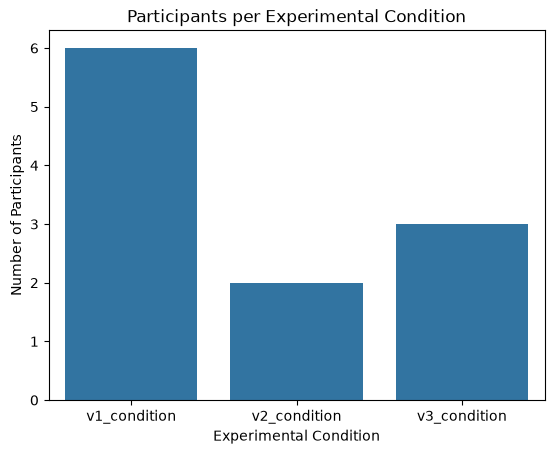

In [78]:
condition_counts = quantitative_data["condition"].value_counts().sort_index()

display(condition_counts)

sns.countplot(data=quantitative_data, x="condition", order=["v1_condition", "v2_condition", "v3_condition"])

plt.title("Participants per Experimental Condition")
plt.xlabel("Experimental Condition")
plt.ylabel("Number of Participants")
plt.show()

### Participant Overview

This section provides a descriptive overview of the participants involved in the experiment.

The analysis considers the number of participants in each experimental condition, together with demographic and behavioural characteristics such as:

- Age group
- Device used during the experiment
- Online shopping frequency
- Daily computer usage

The purpose is to understand the composition of the sample and identify potential differences between experimental groups.

Since the sample is relatively small, these characteristics are primarily used for descriptive purposes rather than drawing conclusions about the general population.

In [79]:
profile_columns = [
    "age_group",
    "device_type",
    "purchase_frequency",
    "computer_usage"
]

for column in profile_columns:

    print(f"\n--- {column} ---")

    display(
        pd.crosstab(
            quantitative_data["condition"],
            quantitative_data[column],
            margins=True
        )
    )


--- age_group ---


age_group,18-21,22-26,27-32,All
condition,,,,
v1_condition,1,4,0,5
v2_condition,0,0,1,1
v3_condition,0,3,0,3
All,1,7,1,9



--- device_type ---


device_type,Computer / Laptop,Smartphone,All
condition,,,
v1_condition,2,3,5
v2_condition,0,1,1
v3_condition,0,3,3
All,2,7,9



--- purchase_frequency ---


purchase_frequency,A couple of times per month,Less than once per month,Multiple times per week,All
condition,,,,
v1_condition,1,3,1,5
v2_condition,0,1,0,1
v3_condition,0,2,1,3
All,1,6,2,9



--- computer_usage ---


computer_usage,5-8 hours,More than 8 hours,All
condition,,,
v1_condition,2,3,5
v2_condition,1,0,1
v3_condition,1,2,3
All,4,5,9


# 3. Data Analysis

## Research Question:
To what extent does cognitive workload (specifically NASA-
TLX mental demand, temporal demand, and frustration) mediate the relationship
between confirmshaming interface design and immediate promotional offer
acceptance (task compliance) in e-commerce checkout flows?

### 3.1 Acceptance Rate between conditions

The study considers three interface conditions:

- **V1 – Control condition:** A clean interface without deceptive patterns.
- **V2 – Confirmshaming condition:** An interface using emotionally manipulative language to discourage users from declining a promotional offer.
- **V3 – Preselected options condition:** An interface where certain options are preselected by default.

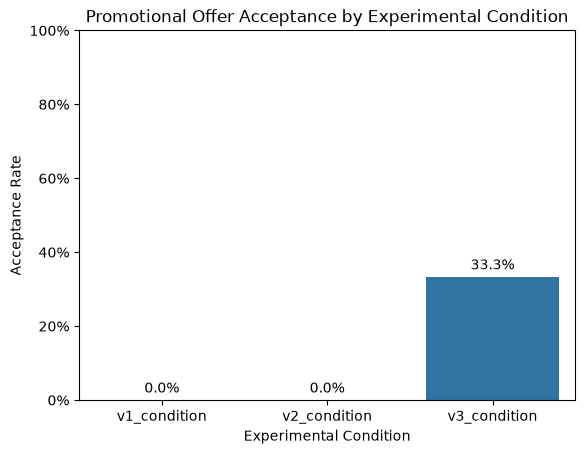

In [80]:
overview = (
    quantitative_data.groupby("condition")
    .agg(
        participants=("participant_id", "nunique"),
        accepted=("acceptance", "sum"),
        valid_responses=("acceptance", "count")
    )
)

overview["not_accepted"] = (
    overview["valid_responses"] - overview["accepted"]
)

overview["acceptance_rate"] = (
    overview["accepted"] / overview["valid_responses"] * 100
)

plot = sns.barplot(
    data=quantitative_data,
    x="condition",
    y="acceptance",
    errorbar=None
)

# values on top of the bars, formatted as percentages
for container in plot.containers:
    plot.bar_label(container, labels=[f"{v.get_height():.1%}" for v in container], padding=3)
#formats 0-1 range to percentage on y-axis (e.g. 0.5 -> 50%)
plot.yaxis.set_major_formatter(PercentFormatter(xmax=1)) 

plt.title("Promotional Offer Acceptance by Experimental Condition")
plt.xlabel("Experimental Condition")
plt.ylabel("Acceptance Rate")
plt.ylim(0, 1)

plt.show()

Did the condition generally change the cognitive workload?

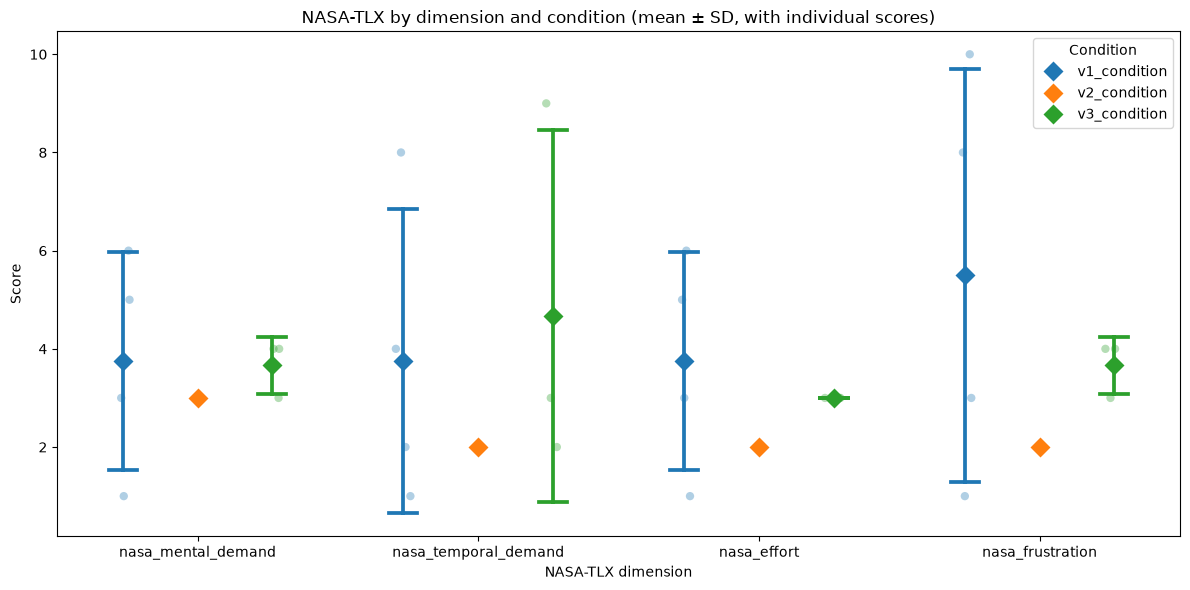

In [81]:
plt.figure(figsize=(12, 6))

dimensions = ["nasa_mental_demand", "nasa_temporal_demand", "nasa_effort", "nasa_frustration"]

df = quantitative_data.melt(
    id_vars="condition",
    value_vars=dimensions,
    var_name="dimension",
    value_name="score",
)

# Raw data points (one dot per participant)
sns.stripplot(
    data=df, x="dimension", y="score", hue="condition",
    dodge=True, alpha=0.35, size=6, legend=False,
)

# Mean +/- SD on top
sns.pointplot(
    data=df, x="dimension", y="score", hue="condition",
    dodge=0.533,            # matches the stripplot spacing for 3 conditions
    linestyle="none", markers="D", markersize=8,
    errorbar="sd", capsize=0.1,
)

plt.xlabel("NASA-TLX dimension")
plt.ylabel("Score")
plt.title("NASA-TLX by dimension and condition (mean ± SD, with individual scores)")
plt.legend(title="Condition")
plt.tight_layout()
plt.show()

## How does the temporal demand diffear with the actual time for deliberation?


### Data overview of temporal releated data

In [82]:
time_comparison = (
    quantitative_data.groupby("condition")
    .agg(
        participants=("participant_id", "count"),
        perceived_time_mean=("nasa_temporal_demand", "mean"),
        perceived_time_median=("nasa_temporal_demand", "median"),
        actual_time_mean=("deliberation_time_sec", "mean"),
        actual_time_median=("deliberation_time_sec", "median"),
        actual_time_std=("deliberation_time_sec", "std")
    )
)

display(time_comparison.round(2))

,participants,perceived_time_mean,perceived_time_median,actual_time_mean,actual_time_median,actual_time_std
condition,,,,,,
v1_condition,6,3.75,3.0,5.29,3.85,3.16
v2_condition,2,2.00,2.0,2.04,2.04,0.04
v3_condition,3,4.67,3.0,23.20,10.88,22.43


### How did the deliberation time change based on the condition?

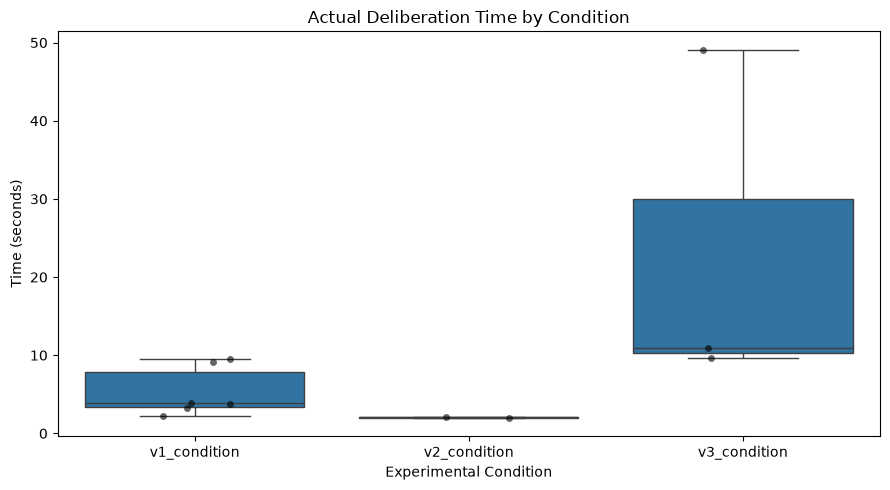

In [83]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=quantitative_data,
    x="condition",
    y="deliberation_time_sec"
)

sns.stripplot(
    data=quantitative_data,
    x="condition",
    y="deliberation_time_sec",
    color="black",
    alpha=0.6,
    jitter=0.15
)

plt.title("Actual Deliberation Time by Condition")
plt.xlabel("Experimental Condition")
plt.ylabel("Time (seconds)")
plt.tight_layout()
plt.show()

### How did they percive the time spent during the test?
To understand this we're using *spearman's rank correlation*:

#### Spearman's Rank Correlation

Spearman's rank correlation is a statistical method used to understand whether two variables tend to increase or decrease together.

The correlation coefficient (ρ) ranges from -1 to +1:
- **+1:** When one variable increases, the other also increases.
- **0:** No clear relationship between the variables.
- **-1:** When one variable increases, the other tends to decrease.

The p-value indicates whether the observed relationship is statistically significant. A value below 0.05 is commonly considered significant.

In this study, Spearman's correlation is used to investigate whether participants who spend more time making a decision (`deliberation_time_sec`) also tend to report higher perceived temporal demand (`nasa_temporal_demand`).

In [84]:
from scipy.stats import spearmanr

rho, p_value = spearmanr(
    quantitative_data["deliberation_time_sec"],
    quantitative_data["nasa_temporal_demand"]
)

print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {p_value:.4f}")

## TODO: This is probably not working cause of the lack of data. We must check carefuly if this works after adding data

Spearman correlation: nan
P-value: nan


Index: 20 entries, 0 to 35
Data columns (total 22 columns):
     Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   timestamp                 20 non-null     str    
 1   participant_id            20 non-null     str    
 2   condition                 20 non-null     str    
 3   action_taken              20 non-null     str    
 4   deliberation_time_sec     20 non-null     float64
 5   email_entered             20 non-null     bool   
 6   checkboxes_checked        20 non-null     str    
 7   is_test                   0 non-null      str    
 8   nasa_mental_demand        16 non-null     float64
 9   nasa_temporal_demand      16 non-null     float64
 10  nasa_performance          2 non-null      float64
 11  nasa_effort               15 non-null     float64
 12  nasa_frustration          16 non-null     float64
 13  willingness_to_recommend  16 non-null     float64
 14  age_group                 18 non-null     str    
 15  device_type               18 non-null     str    
 16  purchase_frequency        18 non-null     str    
 17  computer_usage            18 non-null     str    
 18  pressure_perception       18 non-null     float64
 19  sarcastic_mocking_extent  18 non-null     float64
 20  have_read_popup           19 non-null     str    
 21  acceptance                19 non-null     Int64  
dtypes: Int64(1), bool(1), float64(9), str(11)

TODO: 
 - Change condition_v2 to confirmshaming etc.